<a href="https://colab.research.google.com/github/elenahermososilva-cyber/Visualizaci-n-con-Matplotlib--Seaborn-y-Stream/blob/main/Visualizaci%C3%B3n_con_Matplotlib%2C_Seaborn_y_Streamlit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Gráficos con matplotlib

/tmp/ipykernel_923/1990910107.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([cargos_fem, cargos_masc], labels=['Female', 'Male'], patch_artist=True,


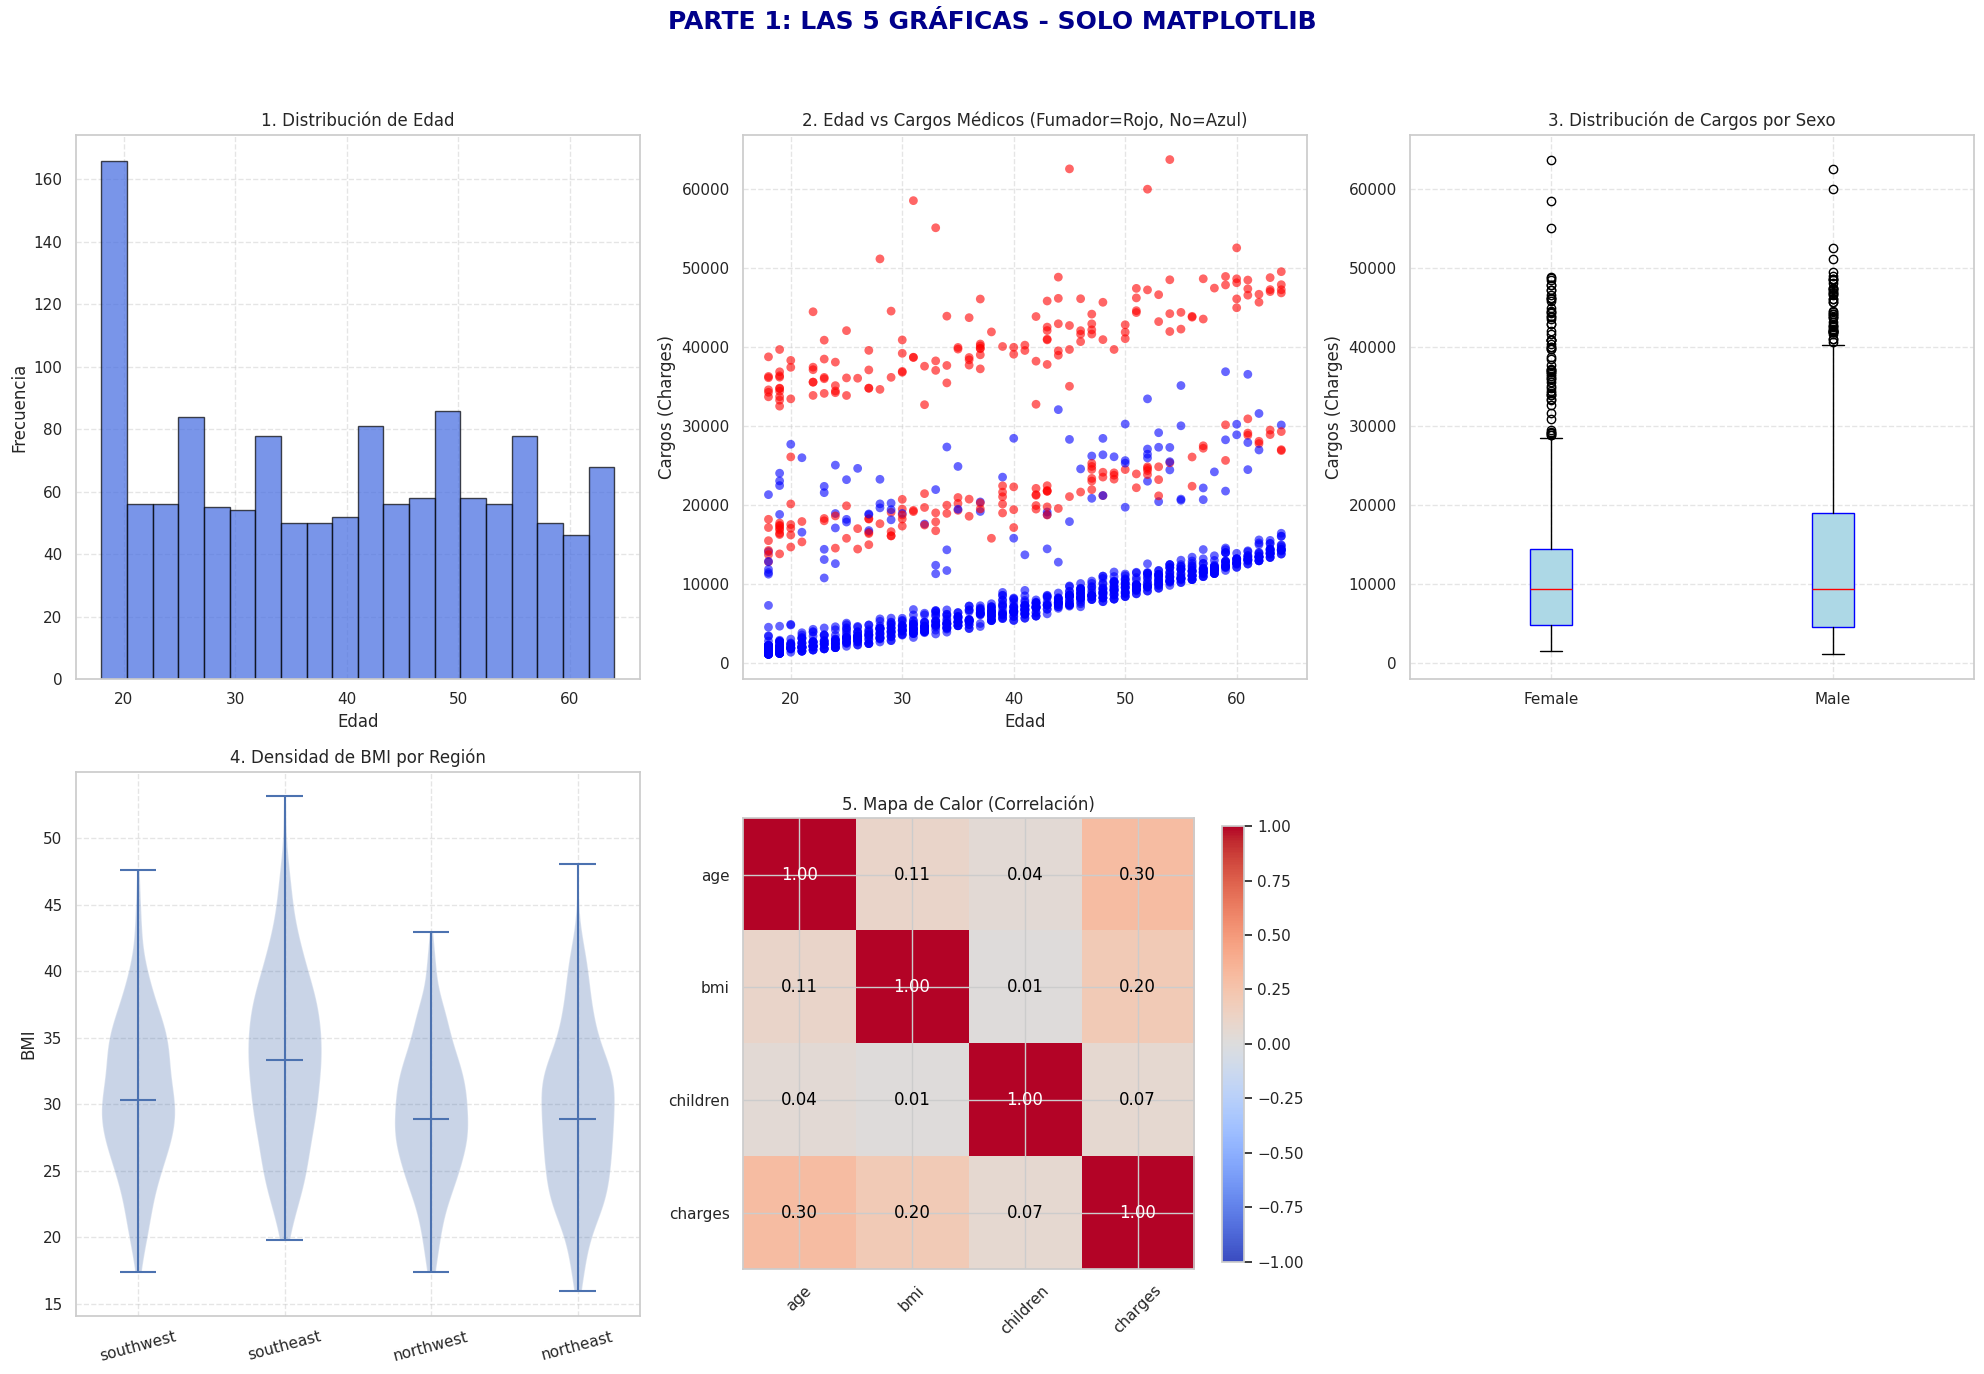

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset de seguros
df = pd.read_csv('/content/drive/MyDrive/Datasets/insurance.csv')

fig1 = plt.figure(figsize=(20, 14))
fig1.suptitle('PARTE 1: LAS 5 GRÁFICAS - SOLO MATPLOTLIB', fontsize=18, fontweight='bold', color='darkblue')

# Gráfica 1: Histograma de Edad (Matplotlib)
plt.subplot(2, 3, 1)
plt.hist(df['age'], bins=20, color='royalblue', edgecolor='black', alpha=0.7)
plt.title('1. Distribución de Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfica 2: Gráfico de Dispersión (Matplotlib)
plt.subplot(2, 3, 2)
colores_fumador = df['smoker'].map({'yes': 'red', 'no': 'blue'})
plt.scatter(df['age'], df['charges'], c=colores_fumador, alpha=0.6, edgecolors='none', s=40)
plt.title('2. Edad vs Cargos Médicos (Fumador=Rojo, No=Azul)')
plt.xlabel('Edad')
plt.ylabel('Cargos (Charges)')
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfica 3: Boxplot (Matplotlib)
plt.subplot(2, 3, 3)
cargos_fem = df[df['sex'] == 'female']['charges']
cargos_masc = df[df['sex'] == 'male']['charges']
plt.boxplot([cargos_fem, cargos_masc], labels=['Female', 'Male'], patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'))
plt.title('3. Distribución de Cargos por Sexo')
plt.ylabel('Cargos (Charges)')
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfica 4: Gráfico de Violín (Matplotlib)
plt.subplot(2, 3, 4)
regiones = df['region'].unique()
datos_bmi_regiones = [df[df['region'] == r]['bmi'] for r in regiones]
plt.violinplot(datos_bmi_regiones, showmeans=False, showmedians=True)
plt.xticks(range(1, len(regiones) + 1), regiones, rotation=15)
plt.title('4. Densidad de BMI por Región')
plt.ylabel('BMI')
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfica 5: Mapa de Calor (Matplotlib)
plt.subplot(2, 3, 5)
num_df = df.select_dtypes(include=[np.number])
corr = num_df.corr().values
columnas = num_df.columns

im = plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, shrink=0.8)
plt.xticks(range(len(columnas)), columnas, rotation=45)
plt.yticks(range(len(columnas)), columnas)
for i in range(len(columnas)):
    for j in range(len(columnas)):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", color="black" if abs(corr[i, j]) < 0.5 else "white")
plt.title('5. Mapa de Calor (Correlación)')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Gráficos con seaborn

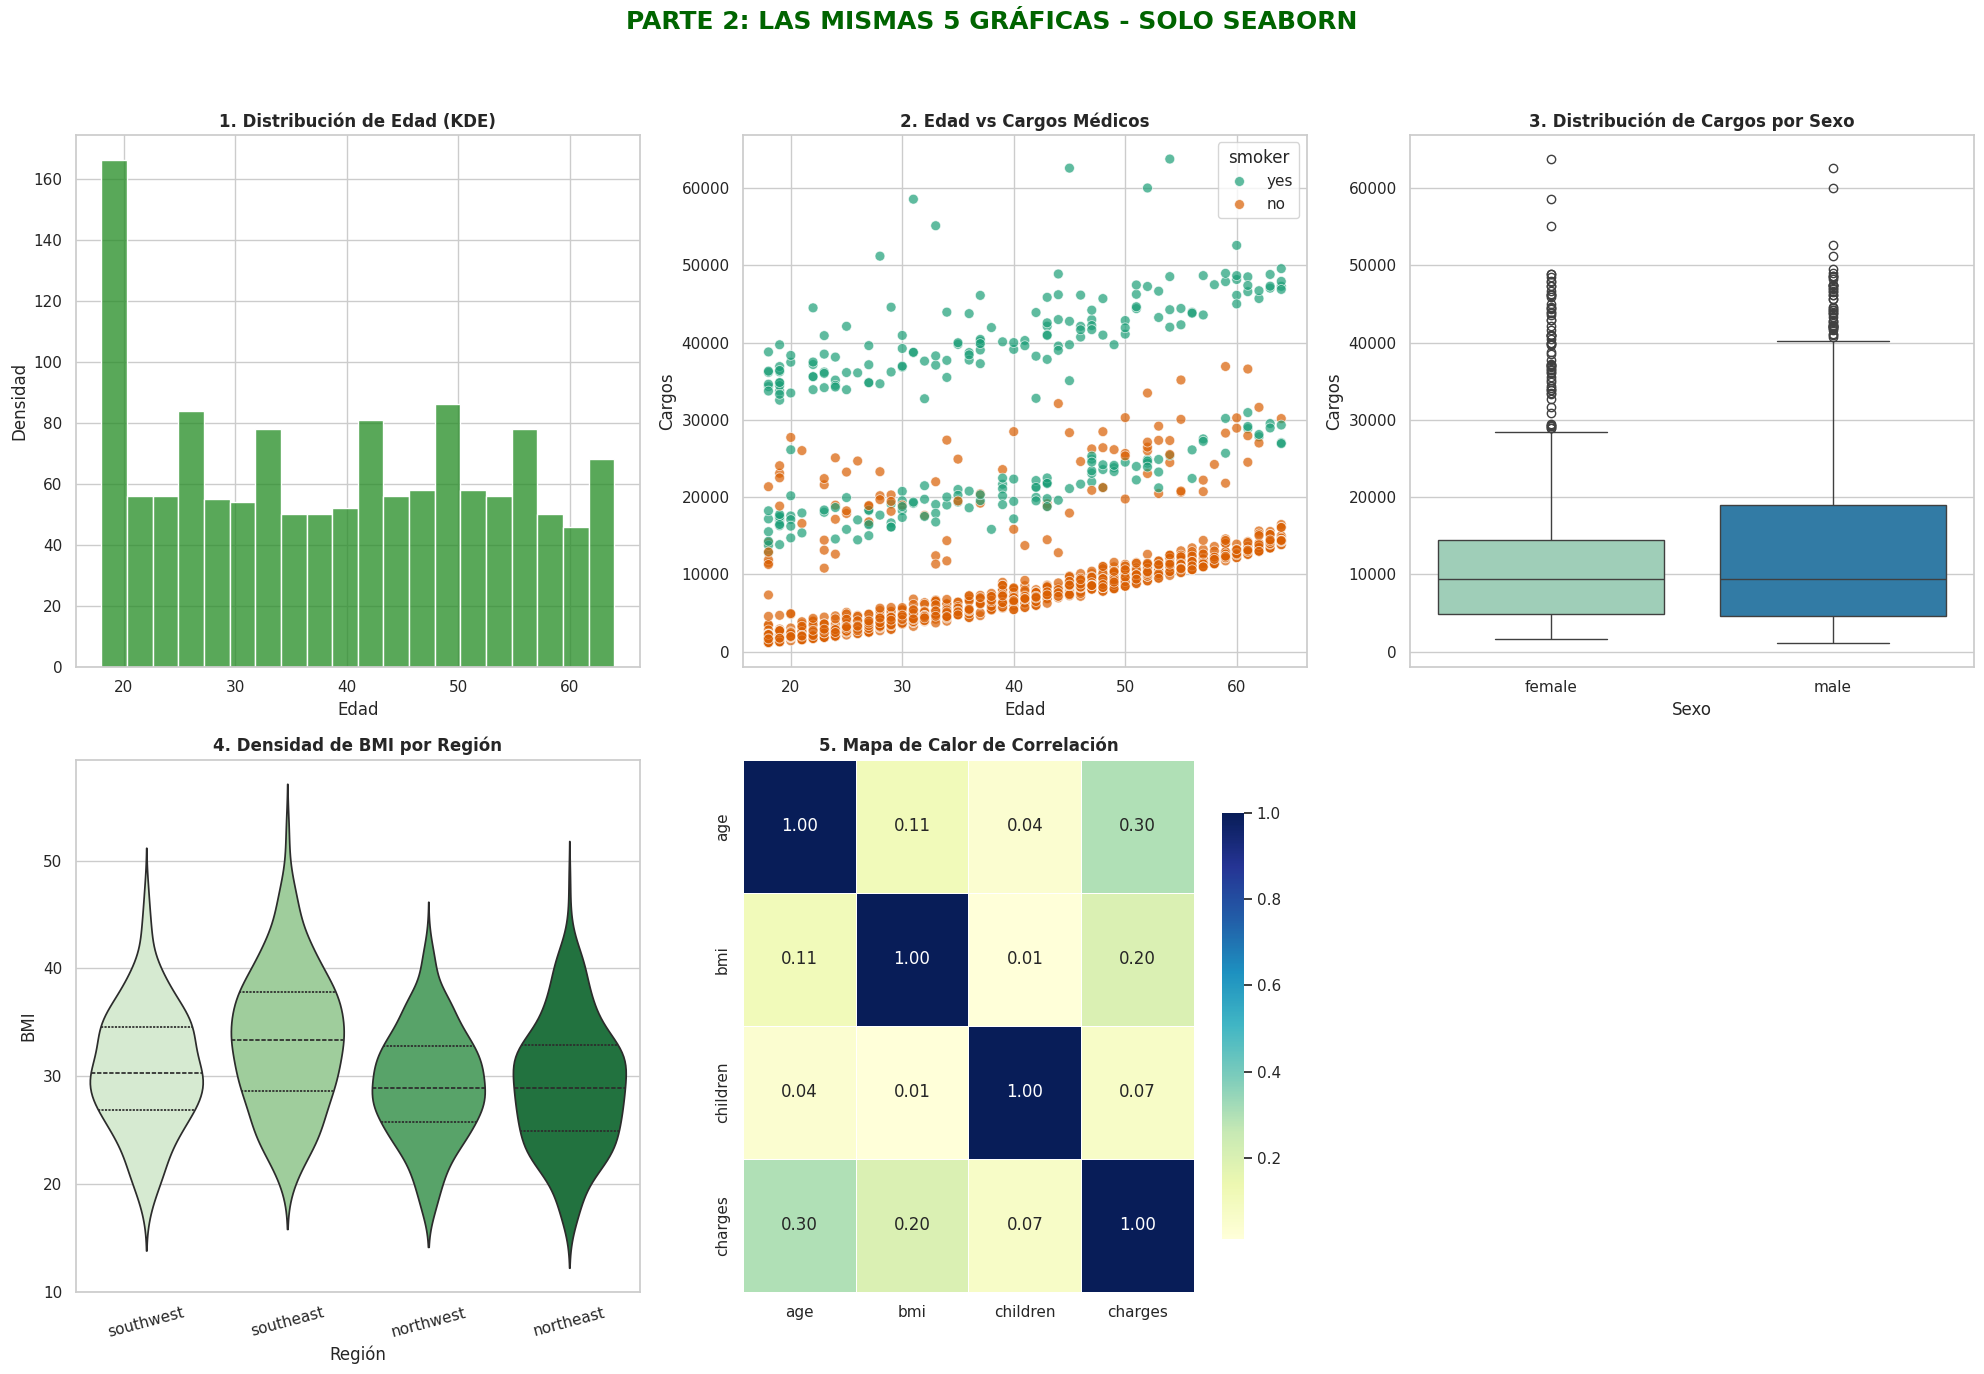

In [11]:
sns.set_theme(style="whitegrid")
fig2 = plt.figure(figsize=(20, 14))
fig2.suptitle('PARTE 2: LAS MISMAS 5 GRÁFICAS - SOLO SEABORN', fontsize=18, fontweight='bold', color='darkgreen')

# Gráfica 1: Histograma de Edad (Seaborn)
plt.subplot(2, 3, 1)
sns.histplot(data=df, x='age', kde=False, color='forestgreen', bins=20)
plt.title('1. Distribución de Edad (KDE)', fontsize=12, fontweight='bold')
plt.xlabel('Edad')
plt.ylabel('Densidad')

# Gráfica 2: Gráfico de Dispersión (Seaborn)
plt.subplot(2, 3, 2)
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette='Dark2', alpha=0.7, s=50)
plt.title('2. Edad vs Cargos Médicos', fontsize=12, fontweight='bold')
plt.xlabel('Edad')
plt.ylabel('Cargos')

# Gráfica 3: Boxplot (Seaborn)
plt.subplot(2, 3, 3)
sns.boxplot(data=df, x='sex', y='charges', palette='YlGnBu', hue='sex', legend=False)
plt.title('3. Distribución de Cargos por Sexo', fontsize=12, fontweight='bold')
plt.xlabel('Sexo')
plt.ylabel('Cargos')

# Gráfica 4: Gráfico de Violín (Seaborn)
plt.subplot(2, 3, 4)
sns.violinplot(data=df, x='region', y='bmi', palette='Greens', hue='region', legend=False, inner="quart")
plt.title('4. Densidad de BMI por Región', fontsize=12, fontweight='bold')
plt.xlabel('Región')
plt.ylabel('BMI')
plt.xticks(rotation=15)

# Gráfica 5: Mapa de Calor (Seaborn)
plt.subplot(2, 3, 5)
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='YlGnBu', fmt=".2f", linewidths=.5, cbar_kws={"shrink": .8})
plt.title('5. Mapa de Calor de Correlación', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Implementación con Streamlit

Para visualizar estos gráficos utilizando **Streamlit**, primero crearemos un script de Python (`app.py`) que defina nuestra aplicación web interactiva.

In [12]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de la página
st.set_page_config(page_title="Dashboard de Seguros Pro", layout="wide", page_icon="📊")

st.title("📊 Dashboard de Seguros Interactivo")
st.write("Filtra los datos en la barra lateral y navega por las pestañas para explorar los análisis dinámicos.")

# 1. Cargar el dataset
@st.cache_data
def load_data():
    try:
        return pd.read_csv('/content/drive/MyDrive/Datasets/insurance.csv')
    except:
        return pd.read_csv('insurance.csv')

try:
    df_raw = load_data()
except Exception as e:
    st.error("No se pudo cargar el dataset 'insurance.csv'. Asegúrate de que está en el mismo directorio.")
    st.stop()

# ==========================================
# BARRA LATERAL (FILTROS INTERACTIVOS)
# ==========================================
st.sidebar.header("⚙️ Filtros de Datos")

# Filtro 1: Sliders de Edad
min_age, max_age = int(df_raw['age'].min()), int(df_raw['age'].max())
edad_seleccionada = st.sidebar.slider(
    "Selecciona el rango de Edad:",
    min_value=min_age,
    max_value=max_age,
    value=(min_age, max_age)
)

# Filtro 2: Selector múltiple de Región
regiones_disponibles = list(df_raw['region'].unique())
regiones_seleccionadas = st.sidebar.multiselect(
    "Selecciona las Regiones:",
    options=regiones_disponibles,
    default=regiones_disponibles
)

# Filtro 3: Botones de opción para Fumador
fumador_opcion = st.sidebar.radio(
    "Filtrar por Fumador:",
    options=["Todos", "Fumadores", "No Fumadores"]
)

# Aplicar Filtros al Dataframe
df = df_raw[
    (df_raw['age'] >= edad_seleccionada[0]) &
    (df_raw['age'] <= edad_seleccionada[1]) &
    (df_raw['region'].isin(regiones_seleccionadas))
]

if fumador_opcion == "Fumadores":
    df = df[df['smoker'] == 'yes']
elif fumador_opcion == "No Fumadores":
    df = df[df['smoker'] == 'no']

# Verificar si quedaron datos tras filtrar
if df.empty:
    st.warning("⚠️ No hay registros que coincidan con los filtros aplicados. Ajusta las opciones en la barra lateral.")
    st.stop()

# ==========================================
# SECCIÓN DE MÉTRICAS (KPIs)
# ==========================================
col_m1, col_m2, col_m3, col_m4 = st.columns(4)
with col_m1:
    st.metric("Total de Registros", f"{len(df):,}")
with col_m2:
    st.metric("Cargos Promedio", f"${df['charges'].mean():,.2f}")
with col_m3:
    st.metric("BMI Promedio", f"{df['bmi'].mean():.2f}")
with col_m4:
    st.metric("Edad Promedio", f"{df['age'].mean():.1f} años")

# ==========================================
# PESTAÑAS
# ==========================================
tab_datos, tab_matplotlib, tab_seaborn = st.tabs([
    "📂 Vista de Datos",
    "📈 Gráficos Matplotlib",
    "🎨 Gráficos Seaborn"
])

# --- PESTAÑA 1: VISTA DE DATOS ---
with tab_datos:
    st.subheader("Muestra de los Datos Filtrados")
    st.dataframe(df, use_container_width=True)

    st.subheader("Estadísticas Descriptivas")
    st.write(df.describe())

# --- PESTAÑA 2: GRÁFICOS CON MATPLOTLIB ---
with tab_matplotlib:
    st.subheader("Visualizaciones generadas exclusivamente con Matplotlib")

    col1, col2 = st.columns(2)
    with col1:
        st.markdown("#### 1. Distribución de Edad")
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.hist(df['age'], bins=20, color='royalblue', edgecolor='black', alpha=0.7)
        ax.set_xlabel('Edad')
        ax.set_ylabel('Frecuencia')
        ax.grid(True, linestyle='--', alpha=0.5)
        st.pyplot(fig)

        st.markdown("#### 3. Distribución de Cargos por Sexo")
        fig, ax = plt.subplots(figsize=(6, 4))
        cargos_fem = df[df['sex'] == 'female']['charges']
        cargos_masc = df[df['sex'] == 'male']['charges']
        datos_boxplot = [cargos_fem, cargos_masc]
        ax.boxplot([x for x in datos_boxplot if not x.empty], tick_labels=[name for name, x in zip(['Female', 'Male'], datos_boxplot) if not x.empty], patch_artist=True,
                    boxprops=dict(facecolor='lightblue', color='blue'),
                    medianprops=dict(color='red'))
        ax.set_ylabel('Cargos (Charges)')
        ax.grid(True, linestyle='--', alpha=0.5)
        st.pyplot(fig)

    with col2:
        st.markdown("#### 2. Edad vs Cargos Médicos")
        fig, ax = plt.subplots(figsize=(6, 4))
        colores_fumador = df['smoker'].map({'yes': 'red', 'no': 'blue'})
        ax.scatter(df['age'], df['charges'], c=colores_fumador, alpha=0.6, edgecolors='none', s=40)
        ax.set_xlabel('Edad')
        ax.set_ylabel('Cargos (Charges)')
        ax.grid(True, linestyle='--', alpha=0.5)
        st.pyplot(fig)

        st.markdown("#### 4. Densidad de BMI por Región")
        fig, ax = plt.subplots(figsize=(6, 4))
        regiones_filtradas = df['region'].unique()
        datos_bmi_regiones = [df[df['region'] == r]['bmi'] for r in regiones_filtradas]
        if datos_bmi_regiones:
            ax.violinplot(datos_bmi_regiones, showmeans=False, showmedians=True)
            ax.set_xticks(range(1, len(regiones_filtradas) + 1))
            ax.set_xticklabels(regiones_filtradas, rotation=15)
            ax.set_ylabel('BMI')
            ax.grid(True, linestyle='--', alpha=0.5)
            st.pyplot(fig)
        else:
            st.write("No hay datos para mostrar el diagrama de violín.")

    st.markdown("#### 5. Mapa de Calor (Correlación)")
    fig, ax = plt.subplots(figsize=(8, 4))
    num_df = df.select_dtypes(include=[np.number])
    if num_df.shape[1] > 1:
        corr = num_df.corr().values
        columnas = num_df.columns
        im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
        fig.colorbar(im, ax=ax, shrink=0.8)
        ax.set_xticks(range(len(columnas)))
        ax.set_xticklabels(columnas, rotation=45)
        ax.set_yticks(range(len(columnas)))
        ax.set_yticklabels(columnas)
        ax.grid(False)  # <-- DESACTIVAR LA CUADRÍCULA AQUÍ
        for i in range(len(columnas)):
            for j in range(len(columnas)):
                ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center",
                        color="black" if abs(corr[i, j]) < 0.5 else "white")
        st.pyplot(fig)
    else:
        st.info("Se requiere más de una variable numérica para correlacionar.")

# --- PESTAÑA 3: GRÁFICOS CON SEABORN ---
with tab_seaborn:
    st.subheader("Visualizaciones generadas exclusivamente con Seaborn")
    sns.set_theme(style="whitegrid")

    col1, col2 = st.columns(2)
    with col1:
        st.markdown("#### 1. Distribución de Edad")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.histplot(data=df, x='age', kde=False, color='forestgreen', bins=20, ax=ax)
        ax.set_xlabel('Edad')
        ax.set_ylabel('Densidad')
        st.pyplot(fig)

        st.markdown("#### 3. Distribución de Cargos por Sexo")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.boxplot(data=df, x='sex', y='charges', palette='YlGnBu', hue='sex', legend=False, ax=ax)
        ax.set_xlabel('Sexo')
        ax.set_ylabel('Cargos')
        st.pyplot(fig)

    with col2:
        st.markdown("#### 2. Edad vs Cargos Médicos")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette='Dark2', alpha=0.7, s=50, ax=ax)
        ax.set_xlabel('Edad')
        ax.set_ylabel('Cargos')
        st.pyplot(fig)

        st.markdown("#### 4. Densidad de BMI por Región")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.violinplot(data=df, x='region', y='bmi', palette='Greens', hue='region', legend=False, inner="quart", ax=ax)
        ax.set_xlabel('Región')
        ax.set_ylabel('BMI')
        plt.xticks(rotation=15)
        st.pyplot(fig)

    st.markdown("#### 5. Mapa de Calor (Correlación)")
    fig, ax = plt.subplots(figsize=(8, 4))
    num_df = df.select_dtypes(include=[np.number])
    if num_df.shape[1] > 1:
        sns.heatmap(num_df.corr(), annot=True, cmap='YlGnBu', fmt=".2f", linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
        st.pyplot(fig)
    else:
        st.info("Se requiere más de una variable numérica para correlacionar.")


Overwriting app.py
